In [ ]:
!pip install xgboost adversarial-robustness-toolbox -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 16.6 MB/s eta 0:00:00


In [ ]:
import numpy as np, pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

# Dataset 1: Breast Cancer (built-in)
bc = load_breast_cancer(as_frame=True)
X_bc, y_bc = bc.data, bc.target

# Dataset 2: Pima Diabetes (internet se)
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigree","Age","Outcome"]
db = pd.read_csv(url, names=cols)

# In columns mein 0 ka matlab "missing" hai, isko NaN banao
for c in ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]:
    db[c] = db[c].replace(0, np.nan)

X_db, y_db = db.drop(columns="Outcome"), db["Outcome"]
print(X_bc.shape, X_db.shape)

(569, 30) (768, 8)


In [ ]:
def prepare(X, y, seed=42):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=seed)
    # Missing values train ki median se bharo
    med = X_tr.median()
    X_tr, X_te = X_tr.fillna(med), X_te.fillna(med)
    # Scaling: fit sirf train par
    sc = StandardScaler().fit(X_tr)
    return sc.transform(X_tr), sc.transform(X_te), y_tr.values, y_te.values, sc

data = {
    "BreastCancer": prepare(X_bc, y_bc),
    "Diabetes": prepare(X_db, y_db),
}

In [ ]:
def get_models(seed=42):
    return {
        "LogReg": LogisticRegression(max_iter=1000, random_state=seed),
        "SVM": SVC(kernel="rbf", probability=True, random_state=seed),
        "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed),
        "XGBoost": XGBClassifier(n_estimators=200, eval_metric="logloss",
                                 random_state=seed),
    }

def metrics(model, X, y):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred),
        "Recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "ROC-AUC": roc_auc_score(y, prob),
    }

rows = []
for ds_name, (Xtr, Xte, ytr, yte, sc) in data.items():
    for m_name, model in get_models().items():
        model.fit(Xtr, ytr)
        r = metrics(model, Xte, yte)
        rows.append({"Dataset": ds_name, "Model": m_name, **r})

clean_results = pd.DataFrame(rows).round(4)
print(clean_results)

        Dataset         Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  BreastCancer        LogReg    0.9825     0.9861  0.9861  0.9861   0.9954
1  BreastCancer           SVM    0.9825     0.9861  0.9861  0.9861   0.9950
2  BreastCancer  RandomForest    0.9561     0.9589  0.9722  0.9655   0.9932
3  BreastCancer       XGBoost    0.9561     0.9467  0.9861  0.9660   0.9934
4      Diabetes        LogReg    0.7078     0.6000  0.5000  0.5455   0.8130
5      Diabetes           SVM    0.7403     0.6522  0.5556  0.6000   0.7964
6      Diabetes  RandomForest    0.7468     0.6596  0.5741  0.6139   0.8165
7      Diabetes       XGBoost    0.7597     0.6809  0.5926  0.6337   0.8026


In [ ]:
all_rows = []
for seed in [0, 1, 2, 3, 4]:
    for ds_name, X, y in [("BreastCancer", X_bc, y_bc), ("Diabetes", X_db, y_db)]:
        Xtr, Xte, ytr, yte, _ = prepare(X, y, seed)
        for m_name, model in get_models(seed).items():
            model.fit(Xtr, ytr)
            all_rows.append({"Dataset": ds_name, "Model": m_name,
                             **metrics(model, Xte, yte)})

df = pd.DataFrame(all_rows)
summary = df.groupby(["Dataset", "Model"]).agg(["mean", "std"]).round(4)
print(summary)
summary.to_csv("table1_clean_results.csv")

                          Accuracy         Precision          Recall          \
                              mean     std      mean     std    mean     std   
Dataset      Model                                                             
BreastCancer LogReg         0.9807  0.0073    0.9755  0.0060  0.9944  0.0076   
             RandomForest   0.9649  0.0164    0.9696  0.0063  0.9750  0.0228   
             SVM            0.9719  0.0114    0.9752  0.0060  0.9806  0.0186   
             XGBoost        0.9684  0.0048    0.9699  0.0055  0.9806  0.0124   
Diabetes     LogReg         0.7494  0.0198    0.6949  0.0573  0.5222  0.0461   
             RandomForest   0.7390  0.0249    0.6557  0.0570  0.5556  0.0507   
             SVM            0.7390  0.0249    0.6762  0.0619  0.5074  0.0748   
             XGBoost        0.7377  0.0449    0.6243  0.0685  0.6556  0.0534   

                               F1         ROC-AUC          
                             mean     std    mean     std  

In [ ]:
EPS = [0.0, 0.05, 0.1, 0.2, 0.5]   # 0.0 = clean (graph ke liye)

feat_names = {"BreastCancer": list(X_bc.columns),
              "Diabetes": list(X_db.columns)}
rules = {
    "BreastCancer": {"fixed": [], "inc_only": []},
    "Diabetes": {"fixed": ["DiabetesPedigree"], "inc_only": ["Age", "Pregnancies"]},
}

def fgsm_lr(lr, X, y, eps, constrained, ds, Xtr):
    p = lr.predict_proba(X)[:, 1]
    grad = (p - y)[:, None] * lr.coef_[0][None, :]   # loss ka gradient
    delta = eps * np.sign(grad)
    if constrained:
        names = feat_names[ds]
        for f in rules[ds]["fixed"]:
            delta[:, names.index(f)] = 0
        for f in rules[ds]["inc_only"]:
            j = names.index(f)
            delta[:, j] = np.maximum(delta[:, j], 0)
    X_adv = X + delta
    if constrained:
        X_adv = np.clip(X_adv, Xtr.min(axis=0), Xtr.max(axis=0))
    return X_adv

In [ ]:
rows = []
for ds, (Xtr, Xte, ytr, yte, sc) in data.items():
    models = get_models(42)
    for m in models.values():
        m.fit(Xtr, ytr)
    lr = models["LogReg"]            # surrogate / attacker model

    for constrained in [False, True]:
        kind = "Constrained" if constrained else "Unconstrained"
        for eps in EPS:
            X_adv = fgsm_lr(lr, Xte, yte, eps, constrained, ds, Xtr)
            for m_name, model in models.items():
                clean_pred = model.predict(Xte)
                adv_pred = model.predict(X_adv)
                ok = clean_pred == yte                    # jo pehle sahi thin
                asr = np.mean(adv_pred[ok] != yte[ok])    # kitni palat gayin
                r = metrics(model, X_adv, yte)
                rows.append({"Dataset": ds, "Attack": kind, "Epsilon": eps,
                             "Model": m_name,
                             "Type": "White-box" if m_name == "LogReg" else "Transfer",
                             **r, "ASR": asr})

attack_results = pd.DataFrame(rows).round(4)
attack_results.to_csv("table2_attack_results.csv", index=False)

print(attack_results.pivot_table(index=["Dataset", "Attack", "Model"],
                                 columns="Epsilon", values="Accuracy"))

Epsilon                                    0.00    0.05    0.10    0.20  \
Dataset      Attack        Model                                          
BreastCancer Constrained   LogReg        0.9825  0.9386  0.9035  0.7632   
                           RandomForest  0.9561  0.9298  0.8860  0.8509   
                           SVM           0.9825  0.9474  0.9123  0.7982   
                           XGBoost       0.9561  0.9386  0.8684  0.8158   
             Unconstrained LogReg        0.9825  0.9386  0.9035  0.7632   
                           RandomForest  0.9561  0.9298  0.8860  0.8509   
                           SVM           0.9825  0.9474  0.9123  0.7982   
                           XGBoost       0.9561  0.9386  0.8684  0.8158   
Diabetes     Constrained   LogReg        0.7078  0.6818  0.6753  0.6688   
                           RandomForest  0.7468  0.7338  0.7532  0.6883   
                           SVM           0.7403  0.7273  0.7273  0.7078   
                         

In [ ]:
rows = []
for seed in range(5):
    for ds, (X, y) in {"BreastCancer": (X_bc, y_bc), "Diabetes": (X_db, y_db)}.items():
        Xtr, Xte, ytr, yte, _ = prepare(X, y, seed)
        models = get_models(seed)
        for m in models.values():
            m.fit(Xtr, ytr)
        lr = models["LogReg"]
        for constrained in [False, True]:
            kind = "Constrained" if constrained else "Unconstrained"
            for eps in EPS:
                X_adv = fgsm_lr(lr, Xte, yte, eps, constrained, ds, Xtr)
                for m_name, model in models.items():
                    ok = model.predict(Xte) == yte
                    adv = model.predict(X_adv)
                    rows.append({"Dataset": ds, "Attack": kind, "Epsilon": eps,
                                 "Model": m_name, "Seed": seed,
                                 "Accuracy": accuracy_score(yte, adv),
                                 "ASR": np.mean(adv[ok] != yte[ok])})

res = pd.DataFrame(rows)
summary2 = (res.groupby(["Dataset", "Attack", "Model", "Epsilon"])[["Accuracy", "ASR"]]
              .agg(["mean", "std"]).round(4))
summary2.to_csv("table2_attack_5seeds.csv")
print(summary2.xs("Diabetes", level="Dataset").head(20))

                                 Accuracy             ASR        
                                     mean     std    mean     std
Attack      Model        Epsilon                                 
Constrained LogReg       0.00      0.7506  0.0175  0.0000  0.0000
                         0.05      0.7286  0.0174  0.0275  0.0194
                         0.10      0.7104  0.0270  0.0522  0.0156
                         0.20      0.6753  0.0392  0.0994  0.0308
                         0.50      0.5091  0.0663  0.3221  0.0711
            RandomForest 0.00      0.7390  0.0249  0.0000  0.0000
                         0.05      0.7325  0.0257  0.0194  0.0098
                         0.10      0.7195  0.0162  0.0489  0.0174
                         0.20      0.6792  0.0307  0.1086  0.0291
                         0.50      0.5727  0.1133  0.2522  0.1408
            SVM          0.00      0.7416  0.0222  0.0000  0.0000
                         0.05      0.7351  0.0269  0.0089  0.0089
          

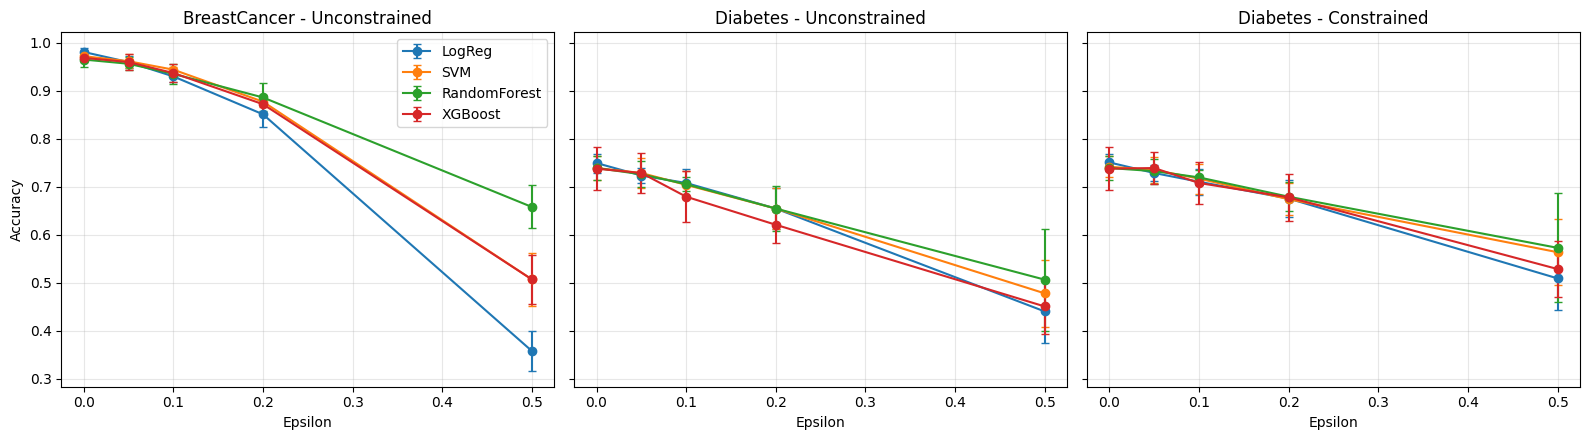

In [ ]:
import matplotlib.pyplot as plt

panels = [("BreastCancer", "Unconstrained"),
          ("Diabetes", "Unconstrained"),
          ("Diabetes", "Constrained")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (ds, kind) in zip(axes, panels):
    sub = res[(res.Dataset == ds) & (res.Attack == kind)]
    for m in ["LogReg", "SVM", "RandomForest", "XGBoost"]:
        g = sub[sub.Model == m].groupby("Epsilon")["Accuracy"].agg(["mean", "std"])
        ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", label=m, capsize=3)
    ax.set_title(f"{ds} - {kind}")
    ax.set_xlabel("Epsilon")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Accuracy")
axes[0].legend()
plt.tight_layout()
plt.savefig("fig1_accuracy_vs_epsilon.png", dpi=300)
plt.show()

In [ ]:
rows = []
for seed in range(5):
    for ds, (X, y) in {"BreastCancer": (X_bc, y_bc), "Diabetes": (X_db, y_db)}.items():
        Xtr, Xte, ytr, yte, _ = prepare(X, y, seed)

        # Clean LR se training adversarial examples (sirf train data)
        lr0 = LogisticRegression(max_iter=1000, random_state=seed).fit(Xtr, ytr)
        Xtr_adv = fgsm_lr(lr0, Xtr, ytr, 0.2, False, ds, Xtr)
        rng = np.random.RandomState(seed)
        Xtr_noise = Xtr + rng.normal(0, 0.2, Xtr.shape)

        train_sets = {
            "None": (Xtr, ytr),
            "AdvTrain": (np.vstack([Xtr, Xtr_adv]), np.concatenate([ytr, ytr])),
            "GaussNoise": (np.vstack([Xtr, Xtr_noise]), np.concatenate([ytr, ytr])),
        }

        for defense, (Xd, yd) in train_sets.items():
            models = get_models(seed)
            for m in models.values():
                m.fit(Xd, yd)
            lr = models["LogReg"]          # attacker = defended LR
            for constrained in [False, True]:
                kind = "Constrained" if constrained else "Unconstrained"
                for eps in [0.0, 0.1, 0.2, 0.5]:
                    X_adv = fgsm_lr(lr, Xte, yte, eps, constrained, ds, Xtr)
                    for m_name, model in models.items():
                        rows.append({"Dataset": ds, "Defense": defense,
                                     "Attack": kind, "Epsilon": eps,
                                     "Model": m_name, "Seed": seed,
                                     "Accuracy": accuracy_score(yte, model.predict(X_adv))})

dres = pd.DataFrame(rows)
summary3 = (dres.groupby(["Dataset", "Attack", "Defense", "Model", "Epsilon"])["Accuracy"]
              .agg(["mean", "std"]).round(4))
summary3.to_csv("table3_defense_5seeds.csv")

view = dres[(dres.Attack == "Unconstrained") & (dres.Epsilon.isin([0.0, 0.2]))]
print(view.pivot_table(index=["Dataset", "Model"],
                       columns=["Defense", "Epsilon"],
                       values="Accuracy").round(3))

Defense                   AdvTrain        GaussNoise          None       
Epsilon                        0.0    0.2        0.0    0.2    0.0    0.2
Dataset      Model                                                       
BreastCancer LogReg          0.954  0.600      0.977  0.825  0.981  0.851
             RandomForest    0.961  0.900      0.963  0.896  0.965  0.886
             SVM             0.956  0.825      0.968  0.879  0.972  0.877
             XGBoost         0.965  0.833      0.967  0.870  0.968  0.872
Diabetes     LogReg          0.747  0.651      0.752  0.658  0.749  0.655
             RandomForest    0.753  0.413      0.742  0.642  0.739  0.655
             SVM             0.736  0.626      0.740  0.657  0.739  0.655
             XGBoost         0.699  0.405      0.732  0.626  0.738  0.621


In [ ]:
def adv_train_set(Xtr, ytr, ds, eps, iters):
    model = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
    for _ in range(iters):
        Xa = fgsm_lr(model, Xtr, ytr, eps, False, ds, Xtr)
        model = LogisticRegression(max_iter=1000).fit(
            np.vstack([Xtr, Xa]), np.concatenate([ytr, ytr]))
    return np.vstack([Xtr, Xa]), np.concatenate([ytr, ytr])

rows = []
for seed in range(5):
    for ds, (X, y) in {"BreastCancer": (X_bc, y_bc), "Diabetes": (X_db, y_db)}.items():
        Xtr, Xte, ytr, yte, _ = prepare(X, y, seed)
        lr0 = LogisticRegression(max_iter=1000, random_state=seed).fit(Xtr, ytr)
        sets = {"None": (Xtr, ytr),
                "Static_0.1": adv_train_set(Xtr, ytr, ds, 0.1, 1),
                "Iter_0.1": adv_train_set(Xtr, ytr, ds, 0.1, 5)}
        for dname, (Xd, yd) in sets.items():
            models = get_models(seed)
            for m in models.values():
                m.fit(Xd, yd)
            attackers = {"CleanLR": lr0, "DefendedLR": models["LogReg"]}
            for aname, atk in attackers.items():
                for eps in [0.0, 0.1, 0.2]:
                    Xadv = fgsm_lr(atk, Xte, yte, eps, False, ds, Xtr)
                    for m_name, model in models.items():
                        rows.append({"Dataset": ds, "Defense": dname, "Attacker": aname,
                                     "Epsilon": eps, "Model": m_name, "Seed": seed,
                                     "Accuracy": accuracy_score(yte, model.predict(Xadv))})

d2 = pd.DataFrame(rows)
d2.groupby(["Dataset", "Defense", "Attacker", "Model", "Epsilon"])["Accuracy"] \
  .agg(["mean", "std"]).round(4).to_csv("table3b_defense_v2.csv")

for e in [0.0, 0.1]:
    print(f"\n=== Epsilon {e} ===")
    print(d2[d2.Epsilon == e].pivot_table(index=["Dataset", "Model"],
          columns=["Defense", "Attacker"], values="Accuracy").round(3))


=== Epsilon 0.0 ===
Defense                   Iter_0.1               None            Static_0.1  \
Attacker                   CleanLR DefendedLR CleanLR DefendedLR    CleanLR   
Dataset      Model                                                            
BreastCancer LogReg          0.972      0.972   0.981      0.981      0.972   
             RandomForest    0.965      0.965   0.965      0.965      0.967   
             SVM             0.972      0.972   0.972      0.972      0.963   
             XGBoost         0.975      0.975   0.968      0.968      0.968   
Diabetes     LogReg          0.743      0.743   0.749      0.749      0.745   
             RandomForest    0.755      0.755   0.739      0.739      0.756   
             SVM             0.738      0.738   0.739      0.739      0.745   
             XGBoost         0.735      0.735   0.738      0.738      0.734   

Defense                               
Attacker                  DefendedLR  
Dataset      Model             

In [ ]:
Xtr, Xte, ytr, yte, _ = prepare(X_db, y_db, 0)
lr = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
d = fgsm_lr(lr, Xte, yte, 0.1, False, "Diabetes", Xtr) - Xte
print("Class 1 patterns:", np.unique(np.sign(d[yte == 1]), axis=0))
print("Class 0 patterns:", np.unique(np.sign(d[yte == 0]), axis=0))

Class 1 patterns: [[-1. -1.  1. -1. -1. -1. -1. -1.]]
Class 0 patterns: [[ 1.  1. -1.  1.  1.  1.  1.  1.]]


In [ ]:
import numpy as np, pandas as pd
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer(as_frame=True)
X_bc, y_bc = bc.data, bc.target

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigree","Age","Outcome"]
db = pd.read_csv(url, names=cols)
X_db, y_db = db.drop(columns="Outcome"), db["Outcome"]

print("BreastCancer shape:", X_bc.shape)
print(y_bc.value_counts())
print()
print("Diabetes shape:", X_db.shape)
print(y_db.value_counts())

BreastCancer shape: (569, 30)
target
1    357
0    212
Name: count, dtype: int64

Diabetes shape: (768, 8)
Outcome
0    500
1    268
Name: count, dtype: int64


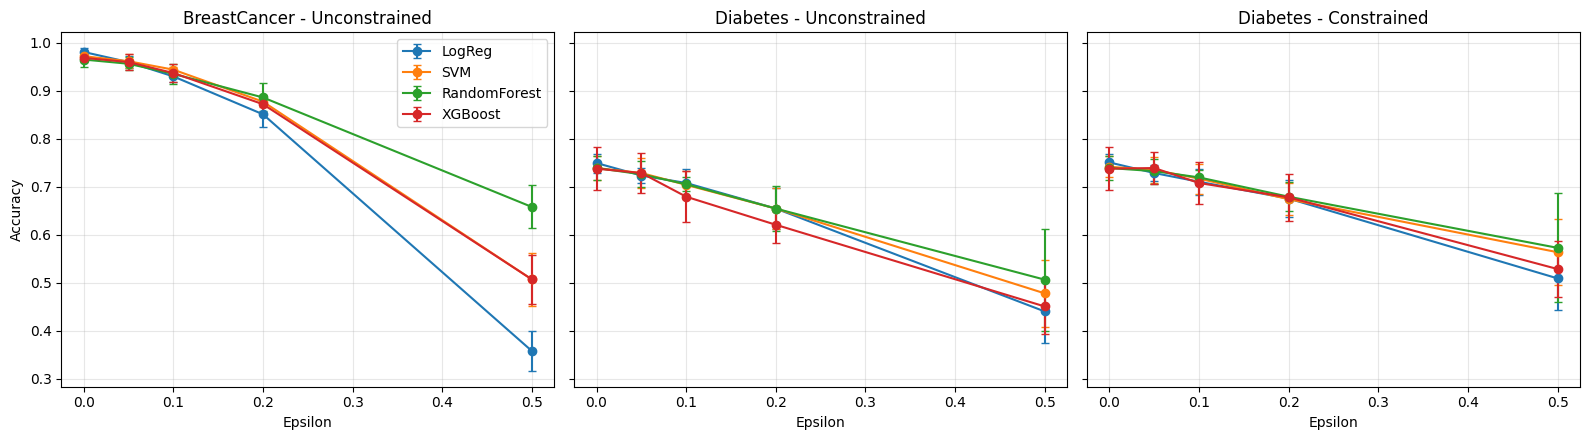

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

        Accuracy             ASR        
            mean     std    mean     std
Epsilon                                 
0.00      0.7506  0.0175  0.0000  0.0000
0.05      0.7286  0.0174  0.0275  0.0194
0.10      0.7104  0.0270  0.0522  0.0156
0.20      0.6753  0.0392  0.0994  0.0308
0.50      0.5091  0.0663  0.3221  0.0711


In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from google.colab import files

# ---- Data ----
bc = load_breast_cancer(as_frame=True)
X_bc, y_bc = bc.data, bc.target
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigree","Age","Outcome"]
db = pd.read_csv(url, names=cols)
for c in ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]:
    db[c] = db[c].replace(0, np.nan)
X_db, y_db = db.drop(columns="Outcome"), db["Outcome"]

def prepare(X, y, seed=42):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=seed)
    med = X_tr.median()
    X_tr, X_te = X_tr.fillna(med), X_te.fillna(med)
    sc = StandardScaler().fit(X_tr)
    return sc.transform(X_tr), sc.transform(X_te), y_tr.values, y_te.values, sc

def get_models(seed=42):
    return {
        "LogReg": LogisticRegression(max_iter=1000, random_state=seed),
        "SVM": SVC(kernel="rbf", probability=True, random_state=seed),
        "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed),
        "XGBoost": XGBClassifier(n_estimators=200, eval_metric="logloss",
                                 random_state=seed),
    }

# ---- Attack ----
EPS = [0.0, 0.05, 0.1, 0.2, 0.5]
feat_names = {"BreastCancer": list(X_bc.columns), "Diabetes": list(X_db.columns)}
rules = {
    "BreastCancer": {"fixed": [], "inc_only": []},
    "Diabetes": {"fixed": ["DiabetesPedigree"], "inc_only": ["Age", "Pregnancies"]},
}

def fgsm_lr(lr, X, y, eps, constrained, ds, Xtr):
    p = lr.predict_proba(X)[:, 1]
    grad = (p - y)[:, None] * lr.coef_[0][None, :]
    delta = eps * np.sign(grad)
    if constrained:
        names = feat_names[ds]
        for f in rules[ds]["fixed"]:
            delta[:, names.index(f)] = 0
        for f in rules[ds]["inc_only"]:
            j = names.index(f)
            delta[:, j] = np.maximum(delta[:, j], 0)
    X_adv = X + delta
    if constrained:
        X_adv = np.clip(X_adv, Xtr.min(axis=0), Xtr.max(axis=0))
    return X_adv

# ---- 5 seeds ----
rows = []
for seed in range(5):
    for ds, (X, y) in {"BreastCancer": (X_bc, y_bc), "Diabetes": (X_db, y_db)}.items():
        Xtr, Xte, ytr, yte, _ = prepare(X, y, seed)
        models = get_models(seed)
        for m in models.values():
            m.fit(Xtr, ytr)
        lr = models["LogReg"]
        for constrained in [False, True]:
            kind = "Constrained" if constrained else "Unconstrained"
            for eps in EPS:
                X_adv = fgsm_lr(lr, Xte, yte, eps, constrained, ds, Xtr)
                for m_name, model in models.items():
                    ok = model.predict(Xte) == yte
                    adv = model.predict(X_adv)
                    rows.append({"Dataset": ds, "Attack": kind, "Epsilon": eps,
                                 "Model": m_name, "Seed": seed,
                                 "Accuracy": accuracy_score(yte, adv),
                                 "ASR": np.mean(adv[ok] != yte[ok])})

res = pd.DataFrame(rows)
summary2 = (res.groupby(["Dataset", "Attack", "Model", "Epsilon"])[["Accuracy", "ASR"]]
              .agg(["mean", "std"]).round(4))
summary2.to_csv("table2_attack_5seeds.csv")

# ---- Graph ----
panels = [("BreastCancer", "Unconstrained"),
          ("Diabetes", "Unconstrained"),
          ("Diabetes", "Constrained")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (ds, kind) in zip(axes, panels):
    sub = res[(res.Dataset == ds) & (res.Attack == kind)]
    for m in ["LogReg", "SVM", "RandomForest", "XGBoost"]:
        g = sub[sub.Model == m].groupby("Epsilon")["Accuracy"].agg(["mean", "std"])
        ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", label=m, capsize=3)
    ax.set_title(f"{ds} - {kind}")
    ax.set_xlabel("Epsilon")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Accuracy")
axes[0].legend()
plt.tight_layout()
plt.savefig("fig1_accuracy_vs_epsilon.png", dpi=300)
plt.show()

# ---- Download ----
files.download("table2_attack_5seeds.csv")
files.download("fig1_accuracy_vs_epsilon.png")

# ---- Check: ye numbers pehle wale se match hone chahiye ----
print(summary2.xs("Diabetes", level="Dataset").loc[("Constrained", "LogReg")].head(5))

In [ ]:
def fmt(s):
    return f"{s.mean():.3f}±{s.std():.3f}"

sub = res[res.Epsilon.isin([0.0, 0.1, 0.2, 0.5])]
print("=== ACCURACY ===")
print(sub.pivot_table(index=["Dataset", "Attack", "Model"],
                      columns="Epsilon", values="Accuracy", aggfunc=fmt).to_string())
print("\n=== ASR ===")
print(sub[sub.Epsilon > 0].pivot_table(index=["Dataset", "Attack", "Model"],
                      columns="Epsilon", values="ASR", aggfunc=fmt).to_string())

d = pd.read_csv("table3b_defense_v2.csv")
print("\n=== DEFENSE v2, eps 0.2 (mean accuracy) ===")
print(d[d.Epsilon == 0.2].pivot_table(index=["Dataset", "Model"],
      columns=["Defense", "Attacker"], values="mean").round(3).to_string())

=== ACCURACY ===
Epsilon                                          0.0          0.1          0.2          0.5
Dataset      Attack        Model                                                           
BreastCancer Constrained   LogReg        0.982±0.006  0.930±0.012  0.851±0.026  0.361±0.044
                           RandomForest  0.965±0.016  0.935±0.020  0.886±0.029  0.658±0.045
                           SVM           0.972±0.011  0.944±0.005  0.877±0.011  0.511±0.056
                           XGBoost       0.968±0.005  0.937±0.019  0.872±0.018  0.507±0.051
             Unconstrained LogReg        0.981±0.007  0.930±0.012  0.851±0.026  0.358±0.041
                           RandomForest  0.965±0.016  0.935±0.020  0.886±0.029  0.658±0.045
                           SVM           0.972±0.011  0.944±0.005  0.877±0.011  0.507±0.056
                           XGBoost       0.968±0.005  0.937±0.019  0.872±0.018  0.507±0.051
Diabetes     Constrained   LogReg        0.751±0.018  0.710±0.0

FileNotFoundError: [Errno 2] No such file or directory: 'table3b_defense_v2.csv'

In [ ]:
from google.colab import files
up = files.upload()

Saving table3b_defense_v2.csv to table3b_defense_v2.csv


In [ ]:
import pandas as pd
d = pd.read_csv("table3b_defense_v2.csv")
print(d[d.Epsilon == 0.2].pivot_table(index=["Dataset", "Model"],
      columns=["Defense", "Attacker"], values="mean").round(3).to_string())

Defense                   Iter_0.1            Static_0.1           
Attacker                   CleanLR DefendedLR    CleanLR DefendedLR
Dataset      Model                                                 
BreastCancer LogReg          0.904      0.740      0.918      0.784
             RandomForest    0.902      0.895      0.912      0.904
             SVM             0.905      0.846      0.926      0.875
             XGBoost         0.896      0.874      0.909      0.891
Diabetes     LogReg          0.690      0.666      0.691      0.670
             RandomForest    0.761      0.538      0.813      0.587
             SVM             0.691      0.648      0.695      0.651
             XGBoost         0.684      0.577      0.717      0.600


In [ ]:
d = pd.read_csv("table3b_defense_v2.csv", keep_default_na=False)
print(d[d.Epsilon == 0.2].pivot_table(index=["Dataset", "Model"],
      columns=["Defense", "Attacker"], values="mean").round(3).to_string())

Defense                   Iter_0.1               None            Static_0.1           
Attacker                   CleanLR DefendedLR CleanLR DefendedLR    CleanLR DefendedLR
Dataset      Model                                                                    
BreastCancer LogReg          0.904      0.740   0.851      0.851      0.918      0.784
             RandomForest    0.902      0.895   0.886      0.886      0.912      0.904
             SVM             0.905      0.846   0.877      0.877      0.926      0.875
             XGBoost         0.896      0.874   0.872      0.872      0.909      0.891
Diabetes     LogReg          0.690      0.666   0.654      0.654      0.691      0.670
             RandomForest    0.761      0.538   0.654      0.654      0.813      0.587
             SVM             0.691      0.648   0.654      0.654      0.695      0.651
             XGBoost         0.684      0.577   0.621      0.621      0.717      0.600


In [ ]:
!pip install -q adversarial-robustness-toolbox xgboost

import numpy as np, pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from art.estimators.classification import BlackBoxClassifier
from art.attacks.evasion import HopSkipJump
from google.colab import files

# ---- Data ----
bc = load_breast_cancer(as_frame=True)
X_bc, y_bc = bc.data, bc.target
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigree","Age","Outcome"]
db = pd.read_csv(url, names=cols)
for c in ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]:
    db[c] = db[c].replace(0, np.nan)
X_db, y_db = db.drop(columns="Outcome"), db["Outcome"]

def prepare(X, y, seed):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    med = Xtr.median()
    Xtr, Xte = Xtr.fillna(med), Xte.fillna(med)
    sc = StandardScaler().fit(Xtr)
    return sc.transform(Xtr), sc.transform(Xte), ytr.values, yte.values

def get_models(seed):
    return {
        "LogReg": LogisticRegression(max_iter=1000, random_state=seed),
        "SVM": SVC(kernel="rbf", probability=True, random_state=seed),
        "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed),
        "XGBoost": XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=seed),
    }

# ---- Settings (pehle chhota test: SEEDS=[0], N=20) ----
SEEDS = [0]
N = 20
THRESH = [0.1, 0.2, 0.5]

rows = []
for seed in SEEDS:
    for ds, (X, y) in {"BreastCancer": (X_bc, y_bc), "Diabetes": (X_db, y_db)}.items():
        Xtr, Xte, ytr, yte = prepare(X, y, seed)
        lo, hi = Xtr.min(axis=0), Xtr.max(axis=0)
        for m_name, model in get_models(seed).items():
            model.fit(Xtr, ytr)
            ok = np.where(model.predict(Xte) == yte)[0][:N]      # sirf sahi predictions
            xs, ys = Xte[ok].astype(np.float32), yte[ok]
            est = BlackBoxClassifier(lambda x, m=model: m.predict_proba(x),
                                     input_shape=(Xtr.shape[1],), nb_classes=2,
                                     clip_values=(lo, hi))
            atk = HopSkipJump(est, targeted=False, norm=np.inf, max_iter=10,
                              max_eval=500, init_eval=50, init_size=50, verbose=False)
            adv = atk.generate(xs)
            flipped = model.predict(adv) != ys
            dist = np.where(flipped, np.abs(adv - xs).max(axis=1), np.inf)
            r = {"Dataset": ds, "Model": m_name, "Seed": seed, "n": len(ys),
                 "median_dist": np.median(dist[flipped]) if flipped.any() else np.nan,
                 "success_any": flipped.mean()}
            for t in THRESH:
                r[f"succ@{t}"] = (dist <= t).mean()
            rows.append(r)
            print(ds, m_name, seed, "done")

hs = pd.DataFrame(rows)
hs.to_csv("table4_hopskipjump.csv", index=False)
files.download("table4_hopskipjump.csv")
print(hs.groupby(["Dataset", "Model"])[["median_dist", "succ@0.1", "succ@0.2", "succ@0.5"]]
        .mean().round(3).to_string())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 18.1 MB/s eta 0:00:00


BreastCancer LogReg 0 done


BreastCancer SVM 0 done


BreastCancer RandomForest 0 done
BreastCancer XGBoost 0 done
Diabetes LogReg 0 done
Diabetes SVM 0 done
Diabetes RandomForest 0 done
Diabetes XGBoost 0 done


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

                           median_dist  succ@0.1  succ@0.2  succ@0.5
Dataset      Model                                                  
BreastCancer LogReg              0.368      0.00      0.05      0.30
             RandomForest        1.044      0.00      0.00      0.15
             SVM                 0.396      0.00      0.05      0.30
             XGBoost             1.337      0.05      0.05      0.15
Diabetes     LogReg              1.137      0.05      0.05      0.10
             RandomForest        1.310      0.00      0.05      0.20
             SVM                 1.018      0.00      0.05      0.10
             XGBoost             0.767      0.05      0.25      0.35


In [ ]:
!pip install -q adversarial-robustness-toolbox xgboost

import numpy as np, pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from art.estimators.classification import BlackBoxClassifier
from art.attacks.evasion import HopSkipJump
from google.colab import files

TEST = False             #first run on True, then make it False and run again

bc = load_breast_cancer(as_frame=True)
X_bc, y_bc = bc.data, bc.target
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigree","Age","Outcome"]
db = pd.read_csv(url, names=cols)
for c in ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]:
    db[c] = db[c].replace(0, np.nan)
X_db, y_db = db.drop(columns="Outcome"), db["Outcome"]

def prepare(X, y, seed):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    med = Xtr.median()
    Xtr, Xte = Xtr.fillna(med), Xte.fillna(med)
    sc = StandardScaler().fit(Xtr)
    return sc.transform(Xtr), sc.transform(Xte), ytr.values, yte.values

def get_models(seed):
    return {
        "LogReg": LogisticRegression(max_iter=1000, random_state=seed),
        "SVM": SVC(kernel="rbf", probability=True, random_state=seed),
        "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed),
        "XGBoost": XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=seed),
    }

SEEDS, N = ([0], 20) if TEST else ([0, 1, 2], 50)
THRESH = [0.1, 0.2, 0.5]

rows = []
for seed in SEEDS:
    rng = np.random.RandomState(seed)
    for ds, (X, y) in {"BreastCancer": (X_bc, y_bc), "Diabetes": (X_db, y_db)}.items():
        Xtr, Xte, ytr, yte = prepare(X, y, seed)
        lo, hi = Xtr.min(axis=0), Xtr.max(axis=0)
        for m_name, model in get_models(seed).items():
            model.fit(Xtr, ytr)
            ok = np.where(model.predict(Xte) == yte)[0][:N]
            xs, ys = Xte[ok].astype(np.float32), yte[ok]

            # init: doosri class ka asli training sample (model ki prediction ke hisab se)
            tr_pred = model.predict(Xtr)
            pool = {c: Xtr[tr_pred == c].astype(np.float32) for c in (0, 1)}
            init = np.stack([pool[1 - int(c)][rng.randint(len(pool[1 - int(c)]))] for c in ys])

            est = BlackBoxClassifier(lambda x, m=model: m.predict_proba(x),
                                     input_shape=(Xtr.shape[1],), nb_classes=2,
                                     clip_values=(lo, hi))
            atk = HopSkipJump(est, targeted=False, norm=np.inf, max_iter=10,
                              max_eval=500, init_eval=50, init_size=50, verbose=False)
            adv = atk.generate(xs, x_adv_init=init)

            failed = np.all(adv == xs, axis=1)
            flipped = model.predict(adv) != ys
            dist = np.where(flipped, np.abs(adv - xs).max(axis=1), np.inf)
            r = {"Dataset": ds, "Model": m_name, "Seed": seed, "n": len(ys),
                 "fail_rate": failed.mean(),
                 "median_dist": np.median(dist[flipped]) if flipped.any() else np.nan}
            for t in THRESH:
                r[f"succ@{t}"] = (dist <= t).mean()
            rows.append(r)
            print(ds, m_name, seed, "done")

hs = pd.DataFrame(rows)
fname = "table4_test.csv" if TEST else "table4_hopskipjump.csv"
hs.to_csv(fname, index=False)
files.download(fname)
print(hs.groupby(["Dataset", "Model"])[["fail_rate", "median_dist", "succ@0.1", "succ@0.2", "succ@0.5"]]
        .mean().round(3).to_string())[]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 9.1 MB/s eta 0:00:00
BreastCancer LogReg 0 done


BreastCancer SVM 0 done
BreastCancer RandomForest 0 done
BreastCancer XGBoost 0 done
Diabetes LogReg 0 done
Diabetes SVM 0 done
Diabetes RandomForest 0 done
Diabetes XGBoost 0 done
BreastCancer LogReg 1 done
BreastCancer SVM 1 done
BreastCancer RandomForest 1 done
BreastCancer XGBoost 1 done
Diabetes LogReg 1 done
Diabetes SVM 1 done
Diabetes RandomForest 1 done
Diabetes XGBoost 1 done
BreastCancer LogReg 2 done
BreastCancer SVM 2 done
BreastCancer RandomForest 2 done
BreastCancer XGBoost 2 done
Diabetes LogReg 2 done
Diabetes SVM 2 done
Diabetes RandomForest 2 done
Diabetes XGBoost 2 done


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

                           fail_rate  median_dist  succ@0.1  succ@0.2  succ@0.5
Dataset      Model                                                             
BreastCancer LogReg            0.000        0.593     0.040     0.093     0.340
             RandomForest      0.000        1.007     0.020     0.040     0.127
             SVM               0.007        0.672     0.007     0.013     0.233
             XGBoost           0.000        0.891     0.027     0.067     0.173
Diabetes     LogReg            0.000        0.852     0.027     0.060     0.233
             RandomForest      0.000        0.808     0.040     0.093     0.267
             SVM               0.000        0.715     0.040     0.093     0.307
             XGBoost           0.000        0.555     0.087     0.180     0.447


In [ ]:
print(hs.groupby(["Dataset", "Model"])[["median_dist", "succ@0.2", "succ@0.5"]]
        .agg(["mean", "std"]).round(3).to_string())

                          median_dist        succ@0.2        succ@0.5       
                                 mean    std     mean    std     mean    std
Dataset      Model                                                          
BreastCancer LogReg             0.593  0.015    0.093  0.046    0.340  0.020
             RandomForest       1.007  0.072    0.040  0.035    0.127  0.012
             SVM                0.672  0.035    0.013  0.012    0.233  0.050
             XGBoost            0.891  0.044    0.067  0.023    0.173  0.023
Diabetes     LogReg             0.852  0.095    0.060  0.035    0.233  0.023
             RandomForest       0.808  0.147    0.093  0.012    0.267  0.061
             SVM                0.715  0.100    0.093  0.076    0.307  0.099
             XGBoost            0.555  0.090    0.180  0.060    0.447  0.081


In [ ]:
!pip install -q adversarial-robustness-toolbox xgboost
import numpy as np, pandas as pd, sklearn, xgboost
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

bc = load_breast_cancer(as_frame=True); X_bc, y_bc = bc.data, bc.target
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigree","Age","Outcome"]
db = pd.read_csv(url, names=cols)
zc = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
print("[0] Zeros treated as missing (out of 768):\n", (db[zc] == 0).sum().to_string())
for c in zc: db[c] = db[c].replace(0, np.nan)
X_db, y_db = db.drop(columns="Outcome"), db["Outcome"]

def prepare(X, y, seed):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    med = Xtr.median(); Xtr, Xte = Xtr.fillna(med), Xte.fillna(med)
    sc = StandardScaler().fit(Xtr)
    return sc.transform(Xtr), sc.transform(Xte), ytr.values, yte.values

def get_models(seed):
    return {"LogReg": LogisticRegression(max_iter=1000, random_state=seed),
            "SVM": SVC(kernel="rbf", probability=True, random_state=seed),
            "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed),
            "XGBoost": XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=seed)}

sets = {"BreastCancer": (X_bc, y_bc), "Diabetes": (X_db, y_db)}

print("\n[1] Exact minimal Linf distance for LogReg (median, 50 correct samples, seeds 0-2)")
print("    Compare with HopSkipJump LogReg medians: BreastCancer 0.593, Diabetes 0.852")
for ds, (X, y) in sets.items():
    meds = []
    for seed in [0, 1, 2]:
        Xtr, Xte, ytr, yte = prepare(X, y, seed)
        lr = LogisticRegression(max_iter=1000, random_state=seed).fit(Xtr, ytr)
        ok = np.where(lr.predict(Xte) == yte)[0][:50]
        meds.append(np.median(np.abs(lr.decision_function(Xte[ok])) / np.abs(lr.coef_[0]).sum()))
    print("   ", ds, round(float(np.mean(meds)), 3))

print("\n[2] Breast Cancer with MALIGNANT (label 0) as positive class, 5 seeds")
rows = []
for seed in range(5):
    Xtr, Xte, ytr, yte = prepare(X_bc, y_bc, seed)
    for n, m in get_models(seed).items():
        m.fit(Xtr, ytr); p = m.predict(Xte)
        rows.append({"Model": n, "Precision": precision_score(yte, p, pos_label=0),
                     "Recall": recall_score(yte, p, pos_label=0), "F1": f1_score(yte, p, pos_label=0)})
print(pd.DataFrame(rows).groupby("Model").agg(["mean", "std"]).round(4).to_string())

names = list(X_db.columns)
def fgsm(lr, X, y, eps, constrained, Xtr):
    p = lr.predict_proba(X)[:, 1]
    d = eps * np.sign((p - y)[:, None] * lr.coef_[0][None, :])
    if constrained:
        d[:, names.index("DiabetesPedigree")] = 0
        for f in ["Age", "Pregnancies"]:
            j = names.index(f); d[:, j] = np.maximum(d[:, j], 0)
    Xa = X + d
    return np.clip(Xa, Xtr.min(axis=0), Xtr.max(axis=0)) if constrained else Xa

print("\n[3] Diabetes: paired difference in accuracy (constrained - unconstrained), 5 seeds")
out = []
for seed in range(5):
    Xtr, Xte, ytr, yte = prepare(X_db, y_db, seed)
    ms = get_models(seed)
    for m in ms.values(): m.fit(Xtr, ytr)
    for eps in [0.2, 0.5]:
        Xu = fgsm(ms["LogReg"], Xte, yte, eps, False, Xtr)
        Xc = fgsm(ms["LogReg"], Xte, yte, eps, True, Xtr)
        for n, m in ms.items():
            out.append({"eps": eps, "Model": n,
                        "diff": accuracy_score(yte, m.predict(Xc)) - accuracy_score(yte, m.predict(Xu))})
print(pd.DataFrame(out).groupby(["eps", "Model"])["diff"].agg(["mean", "std"]).round(3).to_string())

import art
print("\n[4] Versions:", "sklearn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| art", art.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 36.8 MB/s eta 0:00:00
[0] Zeros treated as missing (out of 768):
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11

[1] Exact minimal Linf distance for LogReg (median, 50 correct samples, seeds 0-2)
    Compare with HopSkipJump LogReg medians: BreastCancer 0.593, Diabetes 0.852
    BreastCancer 0.424
    Diabetes 0.623

[2] Breast Cancer with MALIGNANT (label 0) as positive class, 5 seeds
             Precision          Recall              F1        
                  mean     std    mean     std    mean     std
Model                                                         
LogReg          0.9902  0.0134  0.9571  0.0106  0.9734  0.0100
RandomForest    0.9578  0.0376  0.9476  0.0106  0.9524  0.0216
SVM             0.9672  0.0313  0.9571  0.0106  0.9619  0.0150
XGBoost         0.9666  0.0212  0.9476  0.0106  0.9568  0.0060

[3] Diabetes: paired difference in accuracy (constraine

In [ ]:
from google.colab import files
import pandas as pd
up = files.upload()
d1 = pd.read_csv("table3_defense_5seeds.csv", keep_default_na=False)
d2 = pd.read_csv("table3b_defense_v2.csv", keep_default_na=False)
print(d1[(d1.Attack == "Unconstrained") & (d1.Epsilon == 0.2)][["Dataset","Defense","Model","mean","std"]].round(3).to_string(index=False))
print()
print(d2[d2.Epsilon == 0.2][["Dataset","Defense","Attacker","Model","mean","std"]].round(3).to_string(index=False))

Saving table3b_defense_v2.csv to table3b_defense_v2.csv
Saving table3_defense_5seeds.csv to table3_defense_5seeds.csv
     Dataset    Defense        Model  mean   std
BreastCancer   AdvTrain       LogReg 0.600 0.059
BreastCancer   AdvTrain RandomForest 0.900 0.005
BreastCancer   AdvTrain          SVM 0.825 0.047
BreastCancer   AdvTrain      XGBoost 0.833 0.022
BreastCancer GaussNoise       LogReg 0.825 0.022
BreastCancer GaussNoise RandomForest 0.896 0.011
BreastCancer GaussNoise          SVM 0.879 0.017
BreastCancer GaussNoise      XGBoost 0.870 0.011
BreastCancer       None       LogReg 0.851 0.026
BreastCancer       None RandomForest 0.886 0.029
BreastCancer       None          SVM 0.877 0.011
BreastCancer       None      XGBoost 0.872 0.018
    Diabetes   AdvTrain       LogReg 0.651 0.047
    Diabetes   AdvTrain RandomForest 0.413 0.112
    Diabetes   AdvTrain          SVM 0.626 0.049
    Diabetes   AdvTrain      XGBoost 0.405 0.107
    Diabetes GaussNoise       LogReg 0.658 0.038


In [ ]:
import pandas as pd
d1 = pd.read_csv("table3_defense_5seeds.csv", keep_default_na=False)
d2 = pd.read_csv("table3b_defense_v2.csv", keep_default_na=False)

print("[A] Exp 1: clean accuracy (eps 0.0) of defended models")
a = d1[(d1.Attack == "Unconstrained") & (d1.Epsilon == 0.0) & (d1.Defense != "None")]
print(a[["Dataset", "Defense", "Model", "mean", "std"]].round(3).to_string(index=False))

print("\n[B] Exp 2: CleanLR attacker, eps 0.0 and 0.1 (None and Static)")
b = d2[(d2.Attacker == "CleanLR") & (d2.Epsilon.isin([0.0, 0.1])) & (d2.Defense != "Iter_0.1")]
print(b[["Dataset", "Defense", "Epsilon", "Model", "mean", "std"]].round(3).to_string(index=False))

print("\n[C] Diabetes per-seed sanity check")
for seed in range(5):
    Xtr, Xte, ytr, yte = prepare(X_db, y_db, seed)
    ms = get_models(seed)
    for m in ms.values(): m.fit(Xtr, ytr)
    pr, ps = ms["RandomForest"].predict(Xte), ms["SVM"].predict(Xte)
    Xa = fgsm(ms["LogReg"], Xte, yte, 0.2, False, Xtr)
    print(seed, "clean RF/SVM:", round(accuracy_score(yte, pr), 4), round(accuracy_score(yte, ps), 4),
          "| same preds:", round(float((pr == ps).mean()), 3),
          "| eps0.2 LR/RF/SVM:", [round(accuracy_score(yte, ms[k].predict(Xa)), 4)
                                   for k in ["LogReg", "RandomForest", "SVM"]])

[A] Exp 1: clean accuracy (eps 0.0) of defended models
     Dataset    Defense        Model  mean   std
BreastCancer   AdvTrain       LogReg 0.954 0.013
BreastCancer   AdvTrain RandomForest 0.961 0.016
BreastCancer   AdvTrain          SVM 0.956 0.014
BreastCancer   AdvTrain      XGBoost 0.965 0.006
BreastCancer GaussNoise       LogReg 0.977 0.010
BreastCancer GaussNoise RandomForest 0.963 0.013
BreastCancer GaussNoise          SVM 0.968 0.015
BreastCancer GaussNoise      XGBoost 0.967 0.017
    Diabetes   AdvTrain       LogReg 0.747 0.024
    Diabetes   AdvTrain RandomForest 0.753 0.028
    Diabetes   AdvTrain          SVM 0.736 0.037
    Diabetes   AdvTrain      XGBoost 0.699 0.040
    Diabetes GaussNoise       LogReg 0.752 0.012
    Diabetes GaussNoise RandomForest 0.742 0.032
    Diabetes GaussNoise          SVM 0.740 0.030
    Diabetes GaussNoise      XGBoost 0.732 0.041

[B] Exp 2: CleanLR attacker, eps 0.0 and 0.1 (None and Static)
     Dataset    Defense  Epsilon        Model  m

In [1]:
print("hello")

hello


In [2]:
import numpy as np, pandas as pd
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigree","Age","Outcome"]
db = pd.read_csv(url, names=cols)
for c in ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]:
    db[c] = db[c].replace(0, np.nan)
X_db, y_db = db.drop(columns="Outcome"), db["Outcome"]
names = list(X_db.columns)

def prepare(X, y, seed):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    med = Xtr.median(); Xtr, Xte = Xtr.fillna(med), Xte.fillna(med)
    sc = StandardScaler().fit(Xtr)
    return sc.transform(Xtr), sc.transform(Xte), ytr.values, yte.values

def get_models(seed):
    return {"LogReg": LogisticRegression(max_iter=1000, random_state=seed),
            "SVM": SVC(kernel="rbf", probability=True, random_state=seed),
            "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed),
            "XGBoost": XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=seed)}

def fgsm(lr, X, y, eps, Xtr, fixed=False, inc=False, clip=False):
    p = lr.predict_proba(X)[:, 1]
    d = eps * np.sign((p - y)[:, None] * lr.coef_[0][None, :])
    if fixed:
        d[:, names.index("DiabetesPedigree")] = 0
    if inc:
        for f in ["Age", "Pregnancies"]:
            j = names.index(f); d[:, j] = np.maximum(d[:, j], 0)
    Xa = X + d
    if clip:
        Xa = np.clip(Xa, Xtr.min(axis=0), Xtr.max(axis=0))
    return Xa

variants = {"Unconstrained": {}, "Fixed": {"fixed": True}, "IncOnly": {"inc": True},
            "ClipOnly": {"clip": True}, "All": {"fixed": True, "inc": True, "clip": True}}

SEEDS = range(10)
rows = []
for seed in SEEDS:
    Xtr, Xte, ytr, yte = prepare(X_db, y_db, seed)
    ms = get_models(seed)
    for m in ms.values(): m.fit(Xtr, ytr)
    for eps in [0.2, 0.5]:
        for v, kw in variants.items():
            Xa = fgsm(ms["LogReg"], Xte, yte, eps, Xtr, **kw)
            for n, m in ms.items():
                rows.append({"seed": seed, "eps": eps, "variant": v, "model": n,
                             "acc": accuracy_score(yte, m.predict(Xa))})
df = pd.DataFrame(rows)
df.to_csv("table5_ablation_10seeds.csv", index=False)

def summarize(g):
    d = g["diff"].values
    n = len(d); mean = d.mean(); se = d.std(ddof=1) / np.sqrt(n)
    h = stats.t.ppf(0.975, n - 1) * se
    try:
        p = stats.wilcoxon(d).pvalue
    except ValueError:
        p = np.nan
    return pd.Series({"mean_diff": mean, "CI_low": mean - h, "CI_high": mean + h, "wilcoxon_p": p})

base = df[df.variant == "Unconstrained"].set_index(["seed", "eps", "model"])["acc"]
out = df[df.variant != "Unconstrained"].copy()
out["diff"] = out.apply(lambda r: r["acc"] - base[(r["seed"], r["eps"], r["model"])], axis=1)
res = out.groupby(["eps", "variant", "model"]).apply(summarize).round(3)
print(res.to_string())
print("\nMean accuracy (10 seeds):")
print(df.pivot_table(index=["eps", "variant"], columns="model", values="acc").round(3).to_string())

/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


                           mean_diff  CI_low  CI_high  wilcoxon_p
eps variant  model                                               
0.2 All      LogReg            0.018   0.012    0.024       0.002
             RandomForest      0.024   0.011    0.037       0.006
             SVM               0.020   0.011    0.029       0.002
             XGBoost           0.038   0.018    0.057       0.008
    ClipOnly LogReg            0.003  -0.001    0.006       0.250
             RandomForest      0.000   0.000    0.000       1.000
             SVM               0.002  -0.000    0.004       0.250
             XGBoost           0.000   0.000    0.000       1.000
    Fixed    LogReg            0.014   0.008    0.019       0.002
             RandomForest      0.020   0.007    0.033       0.012
             SVM               0.013   0.003    0.023       0.004
             XGBoost           0.029   0.008    0.051       0.025
    IncOnly  LogReg            0.006   0.002    0.010       0.031
          

/tmp/ipykernel_2582/849846430.py:75: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = out.groupby(["eps", "variant", "model"]).apply(summarize).round(3)


In [3]:
rows, W = [], []
for seed in range(10):
    Xtr, Xte, ytr, yte = prepare(X_db, y_db, seed)
    ms = get_models(seed)
    for m in ms.values(): m.fit(Xtr, ytr)
    lr = ms["LogReg"]; W.append(np.abs(lr.coef_[0]))
    p = lr.predict_proba(Xte)[:, 1]
    d0 = 0.5 * np.sign((p - yte)[:, None] * lr.coef_[0][None, :])
    base = {n: accuracy_score(yte, m.predict(Xte + d0)) for n, m in ms.items()}
    for j, f in enumerate(names):
        d = d0.copy(); d[:, j] = 0
        for n, m in ms.items():
            rows.append({"feature": f, "model": n,
                         "gain": accuracy_score(yte, m.predict(Xte + d)) - base[n]})
g = pd.DataFrame(rows).pivot_table(index="feature", columns="model", values="gain").round(3)
g["mean_abs_weight"] = pd.Series(np.mean(W, axis=0), index=names).round(3)
print(g.sort_values("mean_abs_weight", ascending=False).to_string())

model             LogReg  RandomForest    SVM  XGBoost  mean_abs_weight
feature                                                                
Glucose            0.152         0.099  0.132    0.113            1.153
BMI                0.084         0.053  0.062    0.060            0.629
Pregnancies        0.056         0.010  0.030    0.015            0.418
DiabetesPedigree   0.044         0.047  0.062    0.047            0.322
Age                0.014         0.050  0.034    0.058            0.143
BloodPressure      0.010        -0.001  0.001    0.021            0.105
Insulin            0.009        -0.055 -0.006   -0.046            0.100
SkinThickness      0.005         0.006  0.012    0.015            0.056


In [4]:
from itertools import combinations
imm = tuple(sorted(names.index(f) for f in ["Age", "Pregnancies", "DiabetesPedigree"]))
subs = list(combinations(range(8), 3))
res = []
for seed in range(10):
    Xtr, Xte, ytr, yte = prepare(X_db, y_db, seed)
    ms = get_models(seed)
    for m in ms.values(): m.fit(Xtr, ytr)
    lr = ms["LogReg"]
    p = lr.predict_proba(Xte)[:, 1]
    d0 = 0.5 * np.sign((p - yte)[:, None] * lr.coef_[0][None, :])
    for n, m in ms.items():
        base = accuracy_score(yte, m.predict(Xte + d0))
        gains = []
        for s in subs:
            d = d0.copy(); d[:, list(s)] = 0
            gains.append(accuracy_score(yte, m.predict(Xte + d)) - base)
        g = gains[subs.index(imm)]
        res.append({"model": n, "immutable_gain": g, "mean_random3": np.mean(gains),
                    "pct_rank": np.mean(np.array(gains) < g)})
r = pd.DataFrame(res)
print(r.groupby("model")[["immutable_gain", "mean_random3", "pct_rank"]].agg(["mean", "std"]).round(3).to_string())

             immutable_gain        mean_random3        pct_rank       
                       mean    std         mean    std     mean    std
model                                                                 
LogReg                0.119  0.017        0.144  0.016    0.391  0.069
RandomForest          0.100  0.038        0.081  0.058    0.505  0.135
SVM                   0.116  0.027        0.114  0.029    0.479  0.109
XGBoost               0.120  0.026        0.102  0.041    0.543  0.206


In [6]:
!pip install -q xgboost
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from google.colab import files

TEST = False      #first run on True, then make it False and run again
SEEDS = [0] if TEST else list(range(5))
EPOCHS = 30 if TEST else 100
EPS_EVAL = [0.0, 0.05, 0.1, 0.2, 0.5]
EPS_TRAIN = [0.1, 0.2]
EPS_TRANSFER = [0.1, 0.2, 0.5]

bc = load_breast_cancer(as_frame=True); X_bc, y_bc = bc.data, bc.target
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigree","Age","Outcome"]
db = pd.read_csv(url, names=cols)
for c in ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]:
    db[c] = db[c].replace(0, np.nan)
X_db, y_db = db.drop(columns="Outcome"), db["Outcome"]
sets = {"BreastCancer": (X_bc, y_bc), "Diabetes": (X_db, y_db)}

def prepare(X, y, seed):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    med = Xtr.median(); Xtr, Xte = Xtr.fillna(med), Xte.fillna(med)
    sc = StandardScaler().fit(Xtr)
    return sc.transform(Xtr), sc.transform(Xte), ytr.values, yte.values

def make_mlp(d):
    return nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2))

def pgd(model, x, y, eps, steps=20):
    if eps == 0: return x.clone()
    alpha = 2.5 * eps / steps
    xa = x + (torch.rand_like(x) * 2 - 1) * eps
    for _ in range(steps):
        xa.requires_grad_(True)
        g, = torch.autograd.grad(F.cross_entropy(model(xa), y), xa)
        xa = xa.detach() + alpha * g.sign()
        xa = x + torch.clamp(xa - x, -eps, eps)
    return xa.detach()

def train(Xtr, ytr, seed, eps_train=None):
    torch.manual_seed(seed)
    X, y = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(ytr, dtype=torch.long)
    m = make_mlp(X.shape[1]); opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    g = torch.Generator().manual_seed(seed)
    for _ in range(EPOCHS):
        perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), 64):
            idx = perm[i:i+64]; xb, yb = X[idx], y[idx]
            loss = F.cross_entropy(m(xb), yb)
            if eps_train:
                xa = pgd(m, xb, yb, eps_train, steps=10)
                loss = 0.5 * loss + 0.5 * F.cross_entropy(m(xa), yb)
            opt.zero_grad(); loss.backward(); opt.step()
    m.eval(); return m

def acc(m, X, y):
    with torch.no_grad(): return (m(X).argmax(1) == y).float().mean().item()

rows, trows = [], []
for seed in SEEDS:
    for ds, (X, y) in sets.items():
        Xtr, Xte, ytr, yte = prepare(X, y, seed)
        Xt, yt = torch.tensor(Xte, dtype=torch.float32), torch.tensor(yte, dtype=torch.long)
        models = {"MLP_standard": train(Xtr, ytr, seed)}
        for e in EPS_TRAIN:
            models[f"MLP_AT_{e}"] = train(Xtr, ytr, seed, eps_train=e)
        torch.manual_seed(seed)
        for name, m in models.items():
            for eps in EPS_EVAL:
                xa = pgd(m, Xt, yt, eps)
                rows.append({"Dataset": ds, "Model": name, "Seed": seed, "eps": eps, "acc": acc(m, xa, yt)})
        # transfer: standard MLP PGD -> sklearn models
        sk = {"LogReg": LogisticRegression(max_iter=1000, random_state=seed),
              "SVM": SVC(kernel="rbf", probability=True, random_state=seed),
              "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed),
              "XGBoost": XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=seed)}
        for n, m in sk.items(): m.fit(Xtr, ytr)
        for eps in EPS_TRANSFER:
            xa = pgd(models["MLP_standard"], Xt, yt, eps).numpy()
            for n, m in sk.items():
                trows.append({"Dataset": ds, "Model": n, "Seed": seed, "eps": eps,
                              "acc": accuracy_score(yte, m.predict(xa))})
        print(ds, "seed", seed, "done")

R, T = pd.DataFrame(rows), pd.DataFrame(trows)
fn = "table6_mlp_pgd_test.csv" if TEST else "table6_mlp_pgd.csv"
fn2 = "table7_transfer_test.csv" if TEST else "table7_transfer_mlp_pgd.csv"
R.to_csv(fn, index=False); T.to_csv(fn2, index=False)
fmt = lambda s: f"{s.mean():.3f}±{s.std():.3f}" if len(s) > 1 else f"{s.mean():.3f}"
print("\n=== MLP: accuracy under white-box PGD ===")
print(R.pivot_table(index=["Dataset", "Model"], columns="eps", values="acc", aggfunc=fmt).to_string())
print("\n=== PGD crafted on standard MLP, transferred ===")
print(T.pivot_table(index=["Dataset", "Model"], columns="eps", values="acc", aggfunc=fmt).to_string())
files.download(fn); files.download(fn2)

BreastCancer seed 0 done
Diabetes seed 0 done
BreastCancer seed 1 done
Diabetes seed 1 done
BreastCancer seed 2 done
Diabetes seed 2 done
BreastCancer seed 3 done
Diabetes seed 3 done
BreastCancer seed 4 done
Diabetes seed 4 done

=== MLP: accuracy under white-box PGD ===
eps                               0.00         0.05         0.10         0.20         0.50
Dataset      Model                                                                        
BreastCancer MLP_AT_0.1    0.975±0.007  0.958±0.004  0.933±0.013  0.853±0.027  0.465±0.054
             MLP_AT_0.2    0.967±0.007  0.961±0.010  0.940±0.011  0.884±0.027  0.586±0.071
             MLP_standard  0.970±0.012  0.947±0.006  0.919±0.013  0.811±0.026  0.311±0.034
Diabetes     MLP_AT_0.1    0.744±0.044  0.712±0.040  0.653±0.052  0.532±0.063  0.247±0.046
             MLP_AT_0.2    0.748±0.028  0.709±0.031  0.677±0.040  0.608±0.051  0.338±0.045
             MLP_standard  0.734±0.043  0.674±0.042  0.601±0.042  0.482±0.045  0.166±0.031

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
from scipy import stats
rows = []
for ds in R.Dataset.unique():
    for eps in [0.1, 0.2, 0.5]:
        base = R[(R.Dataset == ds) & (R.Model == "MLP_standard") & (R.eps == eps)].sort_values("Seed")["acc"].values
        for m in ["MLP_AT_0.1", "MLP_AT_0.2"]:
            a = R[(R.Dataset == ds) & (R.Model == m) & (R.eps == eps)].sort_values("Seed")["acc"].values
            d = a - base; n = len(d)
            h = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
            rows.append({"Dataset": ds, "eps": eps, "model": m, "gain": d.mean(),
                         "CI_low": d.mean() - h, "CI_high": d.mean() + h, "seeds_improved": int((d > 0).sum())})
print(pd.DataFrame(rows).round(3).to_string(index=False))
import torch, sklearn; print("torch", torch.__version__)

     Dataset  eps      model  gain  CI_low  CI_high  seeds_improved
BreastCancer  0.1 MLP_AT_0.1 0.014  -0.006    0.034               3
BreastCancer  0.1 MLP_AT_0.2 0.021  -0.000    0.042               5
BreastCancer  0.2 MLP_AT_0.1 0.042   0.007    0.077               4
BreastCancer  0.2 MLP_AT_0.2 0.074   0.028    0.120               5
BreastCancer  0.5 MLP_AT_0.1 0.154   0.077    0.232               5
BreastCancer  0.5 MLP_AT_0.2 0.275   0.171    0.380               5
    Diabetes  0.1 MLP_AT_0.1 0.052   0.030    0.074               5
    Diabetes  0.1 MLP_AT_0.2 0.075   0.063    0.088               5
    Diabetes  0.2 MLP_AT_0.1 0.051   0.014    0.087               5
    Diabetes  0.2 MLP_AT_0.2 0.126   0.115    0.137               5
    Diabetes  0.5 MLP_AT_0.1 0.081   0.046    0.115               5
    Diabetes  0.5 MLP_AT_0.2 0.171   0.142    0.201               5
torch 2.11.0+cpu


In [2]:
!pip install -q xgboost
import numpy as np, pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from google.colab import files

TEST = False      #first run on True, then make it False and run again
SEEDS = [0] if TEST else list(range(10))
NRAND = 20 if TEST else 100
EPS = [0.0, 0.05, 0.1, 0.2, 0.5]

# ---------- Data ----------
bc = load_breast_cancer(as_frame=True); X_bc, y_bc = bc.data, bc.target
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigree","Age","Outcome"]
db = pd.read_csv(url, names=cols)
for c in ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]:
    db[c] = db[c].replace(0, np.nan)
X_db, y_db = db.drop(columns="Outcome"), db["Outcome"]
names_db = list(X_db.columns)

hcols = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal","num"]
url_h = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
try:
    hd = pd.read_csv(url_h, names=hcols, na_values="?")
except Exception as e:
    print("UCI download failed:", e)
    print("processed.cleveland.data (bina header ki file) upload karo:")
    up = files.upload()
    hd = pd.read_csv(next(iter(up)), names=hcols, na_values="?")
hd["target"] = (hd["num"] > 0).astype(int)
print("Heart:", hd.shape, "| disease:", int(hd.target.sum()), "| missing:", int(hd.isna().sum().sum()))

CONT = ["age","trestbps","chol","thalach","oldpeak","ca"]
BIN = ["sex","fbs","exang"]
CAT = {"cp":[1,2,3,4], "restecg":[0,1,2], "slope":[1,2,3], "thal":[3,6,7]}

def encode(df):
    out = df[CONT + BIN].astype(float).copy()
    for c, lv in CAT.items():
        for l in lv: out[f"{c}_{l}"] = (df[c] == l).astype(float)
    return out

def prepare_heart(seed):
    X, y = hd.drop(columns=["num","target"]), hd["target"]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    Xtr, Xte = Xtr.copy(), Xte.copy()
    for c in CONT:
        m = Xtr[c].median(); Xtr[c] = Xtr[c].fillna(m); Xte[c] = Xte[c].fillna(m)
    for c in BIN + list(CAT):
        m = Xtr[c].mode()[0]; Xtr[c] = Xtr[c].fillna(m); Xte[c] = Xte[c].fillna(m)
    Etr, Ete = encode(Xtr), encode(Xte)
    sc = StandardScaler().fit(Etr)
    return sc.transform(Etr), sc.transform(Ete), ytr.values, yte.values, list(Etr.columns)

def prepare(X, y, seed):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    med = Xtr.median(); Xtr, Xte = Xtr.fillna(med), Xte.fillna(med)
    sc = StandardScaler().fit(Xtr)
    return sc.transform(Xtr), sc.transform(Xte), ytr.values, yte.values

def get_models(seed):
    return {"LogReg": LogisticRegression(max_iter=1000, random_state=seed),
            "SVM": SVC(kernel="rbf", probability=True, random_state=seed),
            "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed),
            "XGBoost": XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=seed)}

def fgsm(lr, X, y, eps, mask=None, inc_idx=(), clip=None):
    p = lr.predict_proba(X)[:, 1]
    d = eps * np.sign((p - y)[:, None] * lr.coef_[0][None, :])
    if mask is not None: d = d * mask
    for j in inc_idx: d[:, j] = np.maximum(d[:, j], 0)
    Xa = X + d
    if clip is not None: Xa = np.clip(Xa, clip[0], clip[1])
    return Xa

rows, clean, ctrl = [], [], []
def log(ds, var, seed, eps, ms, Xte, yte, Xa):
    for n, m in ms.items():
        ok = m.predict(Xte) == yte; adv = m.predict(Xa)
        rows.append({"Dataset": ds, "Variant": var, "Seed": seed, "eps": eps, "Model": n,
                     "acc": accuracy_score(yte, adv), "asr": np.mean(adv[ok] != yte[ok])})

# Table 2 (Breast Cancer, Diabetes)
for seed in SEEDS:
    for ds, (X, y) in {"BreastCancer": (X_bc, y_bc), "Diabetes": (X_db, y_db)}.items():
        Xtr, Xte, ytr, yte = prepare(X, y, seed)
        ms = get_models(seed)
        for m in ms.values(): m.fit(Xtr, ytr)
        lr = ms["LogReg"]
        if ds == "Diabetes":
            mask = np.ones(8); mask[names_db.index("DiabetesPedigree")] = 0
            inc = [names_db.index("Age"), names_db.index("Pregnancies")]
        for eps in EPS:
            log(ds, "Unconstrained", seed, eps, ms, Xte, yte, fgsm(lr, Xte, yte, eps))
            if ds == "Diabetes":
                log(ds, "Constrained", seed, eps, ms, Xte, yte,
                    fgsm(lr, Xte, yte, eps, mask, inc, (Xtr.min(axis=0), Xtr.max(axis=0))))

# ---------- Heart ----------
for seed in SEEDS:
    Xtr, Xte, ytr, yte, cn = prepare_heart(seed)
    ms = get_models(seed)
    for m in ms.values(): m.fit(Xtr, ytr)
    lr = ms["LogReg"]
    for n, m in ms.items():
        pr, pb = m.predict(Xte), m.predict_proba(Xte)[:, 1]
        clean.append({"Model": n, "Accuracy": accuracy_score(yte, pr), "Precision": precision_score(yte, pr),
                      "Recall": recall_score(yte, pr), "F1": f1_score(yte, pr), "ROC-AUC": roc_auc_score(yte, pb)})
    mask_cont = np.array([1.0 if c in CONT else 0.0 for c in cn]); age_idx = [cn.index("age")]
    for eps in EPS:
        log("Heart", "All", seed, eps, ms, Xte, yte, fgsm(lr, Xte, yte, eps))
        log("Heart", "ContOnly", seed, eps, ms, Xte, yte, fgsm(lr, Xte, yte, eps, mask_cont))
        log("Heart", "ContOnly_AgeInc", seed, eps, ms, Xte, yte, fgsm(lr, Xte, yte, eps, mask_cont, age_idx))
    # control: ContOnly versus random sets of the same size (eps 0.5)
    rng = np.random.RandomState(seed); k = int(mask_cont.sum())
    p = lr.predict_proba(Xte)[:, 1]; D = 0.5 * np.sign((p - yte)[:, None] * lr.coef_[0][None, :])
    for n, m in ms.items():
        a_c = accuracy_score(yte, m.predict(Xte + D * mask_cont))
        ra = []
        for _ in range(NRAND):
            mk = np.zeros(len(cn)); mk[rng.choice(len(cn), k, replace=False)] = 1
            ra.append(accuracy_score(yte, m.predict(Xte + D * mk)))
        ctrl.append({"Model": n, "contonly_acc": a_c, "random_mean": np.mean(ra),
                     "frac_random_stronger": np.mean(np.array(ra) < a_c)})
    print("heart seed", seed, "done")

R = pd.DataFrame(rows)
R.to_csv("table8_fgsm_10seeds.csv", index=False)
fmt = lambda s: f"{s.mean():.3f}±{s.std():.3f}" if len(s) > 1 else f"{s.mean():.3f}"

print("\n=== HEART clean (10 seeds) ===")
print(pd.DataFrame(clean).groupby("Model").agg(fmt).to_string())
print("\n=== TABLE 2 recomputed: accuracy (BreastCancer, Diabetes) ===")
print(R[R.Dataset != "Heart"].pivot_table(index=["Dataset", "Variant", "Model"], columns="eps", values="acc", aggfunc=fmt).to_string())
print("\n=== TABLE 2 recomputed: ASR ===")
print(R[(R.Dataset != "Heart") & (R.eps > 0)].pivot_table(index=["Dataset", "Variant", "Model"], columns="eps", values="asr", aggfunc=fmt).to_string())
print("\n=== HEART accuracy under FGSM ===")
print(R[R.Dataset == "Heart"].pivot_table(index=["Variant", "Model"], columns="eps", values="acc", aggfunc=fmt).to_string())
print("\n=== HEART control (eps 0.5): ContOnly vs random sets of", k, "features ===")
print(pd.DataFrame(ctrl).groupby("Model").agg(fmt).to_string())
files.download("table8_fgsm_10seeds.csv")

Heart: (303, 15) | disease: 139 | missing: 6
heart seed 0 done
heart seed 1 done
heart seed 2 done
heart seed 3 done
heart seed 4 done
heart seed 5 done
heart seed 6 done
heart seed 7 done
heart seed 8 done
heart seed 9 done

=== HEART clean (10 seeds) ===
                 Accuracy    Precision       Recall           F1      ROC-AUC
Model                                                                        
LogReg        0.836±0.058  0.864±0.070  0.764±0.083  0.810±0.071  0.903±0.041
RandomForest  0.816±0.057  0.827±0.071  0.761±0.081  0.791±0.067  0.895±0.037
SVM           0.805±0.056  0.810±0.089  0.761±0.081  0.781±0.064  0.873±0.037
XGBoost       0.780±0.046  0.783±0.069  0.729±0.063  0.753±0.051  0.854±0.041

=== TABLE 2 recomputed: accuracy (BreastCancer, Diabetes) ===
eps                                             0.00         0.05         0.10         0.20         0.50
Dataset      Variant       Model                                                                        
Br

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# Part 1: Table 1 with 10 seeds (positive class: malignant for BreastCancer, diabetic for Diabetes)
rows = []
for seed in range(10):
    for ds, (X, y, pos) in {"BreastCancer": (X_bc, y_bc, 0), "Diabetes": (X_db, y_db, 1)}.items():
        Xtr, Xte, ytr, yte = prepare(X, y, seed)
        for n, m in get_models(seed).items():
            m.fit(Xtr, ytr); p = m.predict(Xte)
            prob = m.predict_proba(Xte)[:, list(m.classes_).index(pos)]
            rows.append({"Dataset": ds, "Model": n, "Accuracy": accuracy_score(yte, p),
                         "Precision": precision_score(yte, p, pos_label=pos),
                         "Recall": recall_score(yte, p, pos_label=pos),
                         "F1": f1_score(yte, p, pos_label=pos),
                         "ROC-AUC": roc_auc_score(yte == pos, prob)})
T1 = pd.DataFrame(rows)
T1.to_csv("table1_clean_10seeds.csv", index=False)
print("=== Table 1, 10 seeds ===")
print(T1.groupby(["Dataset", "Model"]).agg(fmt).to_string())

# Part 2: do tiny shifts of binary/one-hot columns break XGBoost on Heart?
res = []
for seed in range(10):
    Xtr, Xte, ytr, yte, cn = prepare_heart(seed)
    lr = LogisticRegression(max_iter=1000, random_state=seed).fit(Xtr, ytr)
    mk = np.array([0.0 if c in CONT else 1.0 for c in cn])
    models = {"RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed),
              "XGB_hist": XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=seed, tree_method="hist"),
              "XGB_exact": XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=seed, tree_method="exact")}
    for n, m in models.items():
        m.fit(Xtr, ytr)
        for eps in [0.0, 0.05, 0.5]:
            Xa = fgsm(lr, Xte, yte, eps, mask=mk)
            res.append({"Model": n, "eps": eps, "acc": accuracy_score(yte, m.predict(Xa))})
print("\n=== Heart: only binary/one-hot columns perturbed ===")
print(pd.DataFrame(res).pivot_table(index="Model", columns="eps", values="acc", aggfunc=fmt).to_string())
files.download("table1_clean_10seeds.csv")

=== Table 1, 10 seeds ===
                              Accuracy    Precision       Recall           F1      ROC-AUC
Dataset      Model                                                                        
BreastCancer LogReg        0.982±0.011  0.979±0.025  0.971±0.019  0.975±0.014  0.998±0.001
             RandomForest  0.965±0.012  0.951±0.029  0.955±0.018  0.953±0.016  0.989±0.010
             SVM           0.975±0.011  0.965±0.031  0.967±0.017  0.966±0.015  0.997±0.002
             XGBoost       0.971±0.009  0.964±0.020  0.957±0.019  0.961±0.012  0.996±0.004
Diabetes     LogReg        0.754±0.024  0.697±0.060  0.543±0.067  0.606±0.040  0.830±0.033
             RandomForest  0.751±0.032  0.672±0.068  0.583±0.061  0.621±0.042  0.820±0.037
             SVM           0.744±0.030  0.676±0.057  0.528±0.086  0.588±0.060  0.817±0.035
             XGBoost       0.739±0.035  0.630±0.056  0.633±0.056  0.630±0.043  0.785±0.036

=== Heart: only binary/one-hot columns perturbed ===
eps       

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
res = []
for seed in range(10):
    for ds, (X, y) in {"Diabetes": (X_db, y_db), "BreastCancer": (X_bc, y_bc)}.items():
        Xtr, Xte, ytr, yte = prepare(X, y, seed)
        lr = LogisticRegression(max_iter=1000, random_state=seed).fit(Xtr, ytr)
        ms = {"XGB_hist": XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=seed, tree_method="hist"),
              "XGB_exact": XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=seed, tree_method="exact")}
        for m in ms.values(): m.fit(Xtr, ytr)
        for eps in [0.0, 0.05, 0.1, 0.2, 0.5]:
            Xa = fgsm(lr, Xte, yte, eps)
            for n, m in ms.items():
                ok = m.predict(Xte) == yte; adv = m.predict(Xa)
                res.append({"Dataset": ds, "Model": n, "eps": eps, "acc": accuracy_score(yte, adv),
                            "asr": np.mean(adv[ok] != yte[ok])})
        if ds == "Diabetes":                     # only the integer feature Pregnancies is shifted
            mk = np.zeros(8); mk[names_db.index("Pregnancies")] = 1
            for eps in [0.05, 0.5]:
                Xa = fgsm(lr, Xte, yte, eps, mask=mk)
                for n, m in ms.items():
                    res.append({"Dataset": "Diabetes_PregnanciesOnly", "Model": n, "eps": eps,
                                "acc": accuracy_score(yte, m.predict(Xa)), "asr": np.nan})
E = pd.DataFrame(res)
print("=== accuracy ===")
print(E.pivot_table(index=["Dataset", "Model"], columns="eps", values="acc", aggfunc=fmt).to_string())
print("\n=== ASR ===")
print(E[E.eps > 0].dropna(subset=["asr"]).pivot_table(index=["Dataset", "Model"], columns="eps", values="asr", aggfunc=fmt).to_string())

=== accuracy ===
eps                                        0.00         0.05         0.10         0.20         0.50
Dataset                  Model                                                                     
BreastCancer             XGB_exact  0.973±0.008  0.952±0.013  0.930±0.017  0.877±0.018  0.539±0.045
                         XGB_hist   0.971±0.009  0.960±0.013  0.939±0.017  0.875±0.020  0.534±0.049
Diabetes                 XGB_exact  0.727±0.041  0.716±0.043  0.690±0.035  0.637±0.061  0.461±0.076
                         XGB_hist   0.739±0.035  0.726±0.041  0.696±0.046  0.634±0.046  0.471±0.074
Diabetes_PregnanciesOnly XGB_exact          NaN  0.727±0.041          NaN          NaN  0.716±0.046
                         XGB_hist           NaN  0.742±0.037          NaN          NaN  0.729±0.038

=== ASR ===
eps                            0.05         0.10         0.20         0.50
Dataset      Model                                                        
BreastCancer XGB_exa

In [2]:
from google.colab import files
files.upload()

Saving table8_fgsm_10seeds.csv to table8_fgsm_10seeds.csv


{'table8_fgsm_10seeds.csv': b'Dataset,Variant,Seed,eps,Model,acc,asr\nBreastCancer,Unconstrained,0,0.0,LogReg,0.9824561403508771,0.0\nBreastCancer,Unconstrained,0,0.0,SVM,0.9649122807017544,0.0\nBreastCancer,Unconstrained,0,0.0,RandomForest,0.9473684210526315,0.0\nBreastCancer,Unconstrained,0,0.0,XGBoost,0.9649122807017544,0.0\nBreastCancer,Unconstrained,0,0.05,LogReg,0.9385964912280702,0.044642857142857144\nBreastCancer,Unconstrained,0,0.05,SVM,0.9385964912280702,0.02727272727272727\nBreastCancer,Unconstrained,0,0.05,RandomForest,0.9473684210526315,0.0\nBreastCancer,Unconstrained,0,0.05,XGBoost,0.9385964912280702,0.02727272727272727\nBreastCancer,Unconstrained,0,0.1,LogReg,0.9298245614035088,0.05357142857142857\nBreastCancer,Unconstrained,0,0.1,SVM,0.9385964912280702,0.02727272727272727\nBreastCancer,Unconstrained,0,0.1,RandomForest,0.9035087719298246,0.046296296296296294\nBreastCancer,Unconstrained,0,0.1,XGBoost,0.9035087719298246,0.06363636363636363\nBreastCancer,Unconstrained,0,0.2

['Unconstrained' 'Constrained' 'All' 'ContOnly' 'ContOnly_AgeInc']


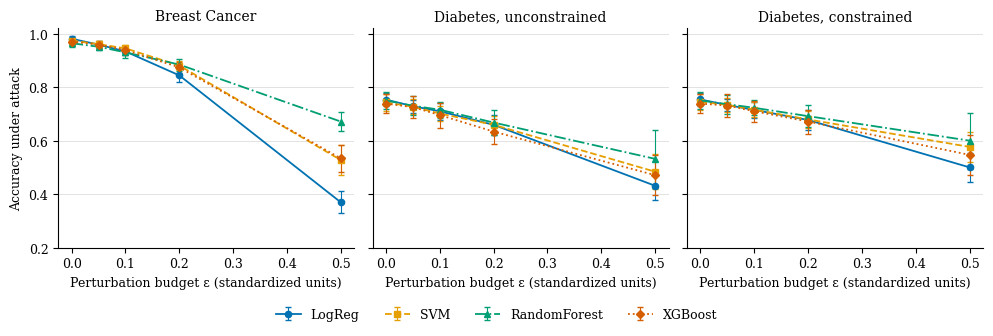

In [3]:
# FINAL Figure 1 (paper): 10-seed FGSM results from table8_fgsm_10seeds.csv
import pandas as pd, matplotlib.pyplot as plt
R = pd.read_csv("table8_fgsm_10seeds.csv", keep_default_na=False)
print(R.Variant.unique())   # check: Unconstrained / Constrained
panels = [("Breast Cancer", "BreastCancer", "Unconstrained"),
          ("Diabetes, unconstrained", "Diabetes", "Unconstrained"),
          ("Diabetes, constrained", "Diabetes", "Constrained")]
sty = {"LogReg": ("#0072B2", "o", "-"), "SVM": ("#E69F00", "s", "--"),
       "RandomForest": ("#009E73", "^", "-."), "XGBoost": ("#D55E00", "D", ":")}
plt.rcParams.update({"font.family": "serif", "font.size": 9})
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), sharey=True)
for ax, (title, ds, var) in zip(axes, panels):
    d = R[(R.Dataset == ds) & (R.Variant == var)]
    for m, (c, mk, ls) in sty.items():
        g = d[d.Model == m].groupby("eps")["acc"].agg(["mean", "std"]).reset_index()
        ax.errorbar(g.eps, g["mean"], yerr=g["std"], color=c, marker=mk, linestyle=ls,
                    markersize=4.5, linewidth=1.3, capsize=2, elinewidth=0.8, label=m)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Perturbation budget ε (standardized units)")
    ax.grid(axis="y", color="#DDDDDD", linewidth=0.6); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
axes[0].set_ylabel("Accuracy under attack"); axes[0].set_ylim(0.2, 1.02)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig("fig1_accuracy_vs_epsilon.png", dpi=200)
plt.show()